In [2]:
# 1. Kaggle kütüphanesini yükle
!pip install -q kaggle

# 2. Kaggle API anahtarını buraya gir (kendi bilgilerine göre düzenle!)
import os
import json

kaggle_api = {
    "username": "muhammetfatihetintas",  # Örn: "ahmetcanalpay"
    "key": "61dcff2dfcef6dac52a665111adf41f7"             # Kaggle API key (kaggle.json içinden)
}

# 3. API bilgilerini sisteme kaydet
os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_api, f)

# 4. Dosya izinlerini ayarla
!chmod 600 /root/.kaggle/kaggle.json

# 5. Veri setini indir (dataset slug: volkandl/car-brand-logos)
!kaggle datasets download -d volkandl/car-brand-logos

# 6. ZIP dosyasını çıkar
!unzip -q car-brand-logos.zip -d car_brand_logos

# 7. Klasör içeriğini kontrol et
import os
for file in os.listdir("car_brand_logos"):
    print(file)


Dataset URL: https://www.kaggle.com/datasets/volkandl/car-brand-logos
License(s): CC0-1.0
 61% 132M/217M [00:00<00:00, 1.38GB/s]
100% 217M/217M [00:00<00:00, 1.39GB/s]
Car_Brand_Logos


Found 2513 images belonging to 8 classes.
Found 400 images belonging to 8 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 52s 561ms/step - accuracy: 0.1477 - loss: 7.4275 - val_accuracy: 0.2525 - val_loss: 3.2824
Epoch 2/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 35s 447ms/step - accuracy: 0.2311 - loss: 4.9664 - val_accuracy: 0.3875 - val_loss: 2.4067
Epoch 3/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 36s 452ms/step - accuracy: 0.2937 - loss: 3.6476 - val_accuracy: 0.4675 - val_loss: 1.9767
Epoch 4/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 35s 446ms/step - accuracy: 0.3665 - loss: 2.8478 - val_accuracy: 0.5150 - val_loss: 1.7743
Epoch 5/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 35s 448ms/step - accuracy: 0.3774 - loss: 2.4667 - val_accuracy: 0.5650 - val_loss: 1.6316
Epoch 6/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 35s 447ms/step - accuracy: 0.4403 - loss: 2.1378 - val_accuracy: 0.5750 - val_loss: 1.4954
Epoch 7/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 35s 448ms/step - accuracy: 0.4371 - loss: 1.9900 - val_accuracy: 0.6100 - val_loss: 1.4186
Epoch 8/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 35s 446ms/step - accuracy: 0.4703 - loss: 1.7548 - val_accu

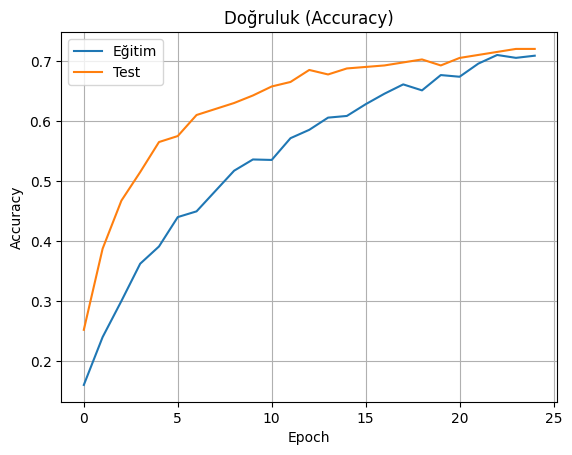

In [3]:
# 1. Gerekli kütüphaneler
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# 2. Yol tanımları
train_dir = "/content/car_brand_logos/Car_Brand_Logos/Train"
test_dir  = "/content/car_brand_logos/Car_Brand_Logos/Test"

# 3. ImageDataGenerator ile veri artırma ve ön işleme
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    zoom_range=0.2,
    rotation_range=10
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# 4. Generator'lar
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# 5. VGG16 modelini yükle (üst katmanlar hariç)
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
for layer in base_model.layers:
    layer.trainable = False  # Katmanları dondur

# 6. Yeni sınıflandırma katmanları
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(train_generator.num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

# 7. Modeli derle
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 8. Eğitim
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=25,
    callbacks=[early_stop]
)

# 9. Doğruluk grafiği
plt.plot(history.history['accuracy'], label='Eğitim')
plt.plot(history.history['val_accuracy'], label='Test')
plt.title("Doğruluk (Accuracy)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# 10. Modeli kaydet
model.save("vgg16_car_brand_model.h5")


In [5]:
from tensorflow.keras.preprocessing import image

img_path = "/content/car_brand_logos/Car_Brand_Logos/Test/lexus/logo1.jpg"  # örnek
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

pred = model.predict(img_array)
predicted_class = np.argmax(pred)
class_name = list(train_generator.class_indices.keys())[predicted_class]

print(f"Tahmin edilen marka: {class_name}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/car_brand_logos/Car_Brand_Logos/Test/lexus/logo1.jpg'